# 4. Regresión
Objetivo: predecir la nota media del segundo semestre (nota_media_2sem) y comparar cuatro modelos de regresión: uno lineal sin regularización (baseline), dos lineales regularizados (Ridge y Lasso) y uno no lineal basado en árboles (Random Forest).

### Imports y carga de datos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv('../rendimiento_estudiantes.csv', sep=';')

leak_cols = [c for c in df.columns if '2sem' in c]
leak_cols.append('objetivo')

X = df.drop(columns=leak_cols)
y = df['nota_media_2sem']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

preprocessor = joblib.load('../preprocessors/preprocessor_reg.pkl')
X_train_t = preprocessor.transform(X_train)
X_test_t  = preprocessor.transform(X_test)

print(f'Train: {X_train_t.shape[0]} instancias | Test: {X_test_t.shape[0]} instancias')
print(f'Target -> media: {y_train.mean():.3f}, std: {y_train.std():.3f}, min: {y_train.min():.3f}, max: {y_train.max():.3f}')

Train: 3539 instancias | Test: 885 instancias
Target -> media: 10.240, std: 5.194, min: 0.000, max: 18.571


### Distribución del target
Se visualiza la distribución de nota_media_2sem en el conjunto de entrenamiento para entender la variabilidad que los modelos deben capturar.

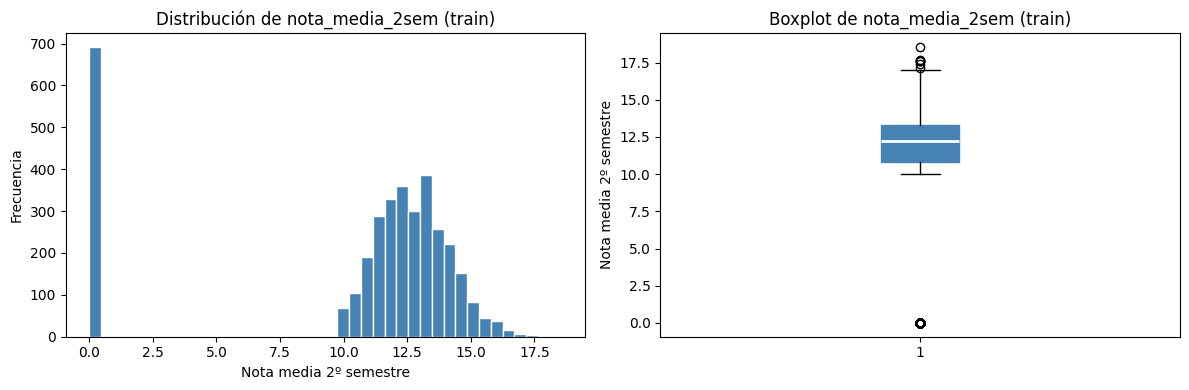

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_train, bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de nota_media_2sem (train)')
axes[0].set_xlabel('Nota media 2º semestre')
axes[0].set_ylabel('Frecuencia')

axes[1].boxplot(y_train, vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='steelblue'),
                medianprops=dict(color='white', linewidth=2))
axes[1].set_title('Boxplot de nota_media_2sem (train)')
axes[1].set_ylabel('Nota media 2º semestre')

plt.tight_layout()
plt.show()

> La distribución concentra la mayor parte de sus valores en torno a 12-13 puntos, con una cola izquierda en 0 (estudiantes que no aprobaron ninguna asignatura en el segundo semestre). Esta asimetría puede dificultar la predicción en los extremos.

### Definición de modelos
Se comparan cuatro modelos con diferentes grados de complejidad:

- **Linear Regression**: regresión lineal base sin regularización. Con 240 features tras el OneHotEncoding, muchas de ellas linealmente dependientes entre sí (colinealidad), el ajuste puede ser numéricamente inestable.
- **Ridge**: igual que Linear Regression pero con regularización L2 (alpha=1), que penaliza coeficientes grandes y mejora la generalización en espacios de alta dimensión.
- **Lasso**: otro modelo de regresión lineal pero con regularización L1 (alpha=1), que además de lo que hace Ridge, hace 'variable selection': puede descartar variables por completo poniendo su peso a 0.
- **Random Forest**: modelo no lineal basado en árboles que captura relaciones complejas entre variables sin suponer linealidad.

In [4]:
modelos = {
    'Linear Regression': LinearRegression(),
    'Ridge Regularization': Ridge(alpha=1.0),
    'Lasso Regularization': Lasso(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1),
}

print('Modelos:')
for nombre, modelo in modelos.items():
    print(f'{nombre}   \t-> {modelo}')

Modelos:
Linear Regression   	-> LinearRegression()
Ridge Regularization   	-> Ridge()
Lasso Regularization   	-> Lasso()
Random Forest   	-> RandomForestRegressor(n_jobs=-1, random_state=0)


### Entrenamiento y evaluación
Se entrena cada modelo y se evalúa sobre el conjunto de test. Las métricas usadas son:

**RMSE (Root Mean Squared Error):** raíz del error cuadrático medio; penaliza más los errores grandes.

**MAE (Mean Absolute Error):** error absoluto medio; más interpretable en la escala original de la nota.

**R² (Coeficiente de determinación):** proporción de varianza del target explicada por el modelo. Un R²=1 es predicción perfecta, R²=0 equivale a predecir siempre la media.

In [5]:
resultados = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train_t, y_train)
    y_pred = modelo.predict(X_test_t)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)

    resultados[nombre] = {'modelo': modelo, 'y_pred': y_pred,
                          'rmse': rmse, 'mae': mae, 'r2': r2}

    print(f'- {nombre} -')
    print(f'RMSE:\t{rmse:.4f}')
    print(f'MAE:\t{mae:.4f}')
    print(f'R²:\t{r2:.4f}')
    print()

- Linear Regression -
RMSE:	5049160895.7343
MAE:	349231264.1242
R²:	-915663117149785344.0000

- Ridge Regularization -
RMSE:	2.5564
MAE:	1.5647
R²:	0.7653

- Lasso Regularization -
RMSE:	2.9037
MAE:	1.9414
R²:	0.6972

- Random Forest -
RMSE:	2.4605
MAE:	1.2763
R²:	0.7826



> Linear Regression establece el baseline puro, pero con estos resultados se ve que la regresión lineal sin regularización no es estable con estas variables: el ajuste produce coeficientes y predicciones extremos, muy probablemente porque las columnas del OneHotEncoding son colineales. El valor exacto de este error depende de la versión de las librerías.

> Ridge y Lasso mejoran considerablemente gracias a la regularización. Son capaces de minimizar más el error, con Ridge siendo ligeramente mejor que Lasso

> Random Forest es el más preciso al capturar relaciones no lineales entre las variables del primer semestre.

### Comparación de modelos
Se excluye Linear Regression de la comparación, ya que su error y R² son tan grandes que no dejan ver las diferencias entre el resto. Se comparan los tres modelos restantes por las tres métricas. El criterio principal es el RMSE, ya que penaliza los errores grandes.

                 Modelo      RMSE       MAE        R²
0  Ridge Regularization  2.556400  1.564659  0.765277
1  Lasso Regularization  2.903674  1.941382  0.697174
2         Random Forest  2.460521  1.276278  0.782554


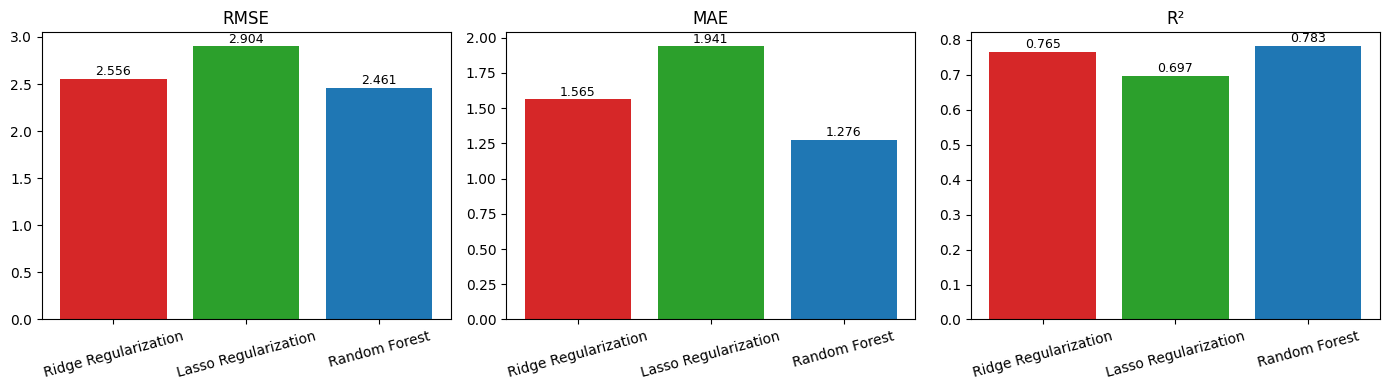

In [6]:
comparacion = pd.DataFrame([
    {'Modelo': nombre, 'RMSE': v['rmse'], 'MAE': v['mae'], 'R²': v['r2']}
    for nombre, v in resultados.items() if nombre != 'Linear Regression'
])

print(comparacion)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metrica in zip(axes, ['RMSE', 'MAE', 'R²']):
    vals = comparacion[metrica].values
    nombres = comparacion['Modelo'].values
    bars = ax.bar(nombres, vals, color=['tab:red', 'tab:green', 'tab:blue'])
    ax.set_title(metrica)
    ax.tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003, f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

> Los gráficos ilustran lo que ya se vio en el apartado anterior: el mejor modelo es Random Forest al poder predecir interacciones entre variables, con Ridge y Lasso obteniendo resultados parecidos siendo Ridge ligeramente mejor. Lasso predice un poco peor a cambio de hacer el variable selection.

### Predicciones vs. valores reales
Se visualizan las predicciones de cada modelo frente a los valores reales del test. Una nube de puntos centrada en la diagonal indica un buen ajuste.

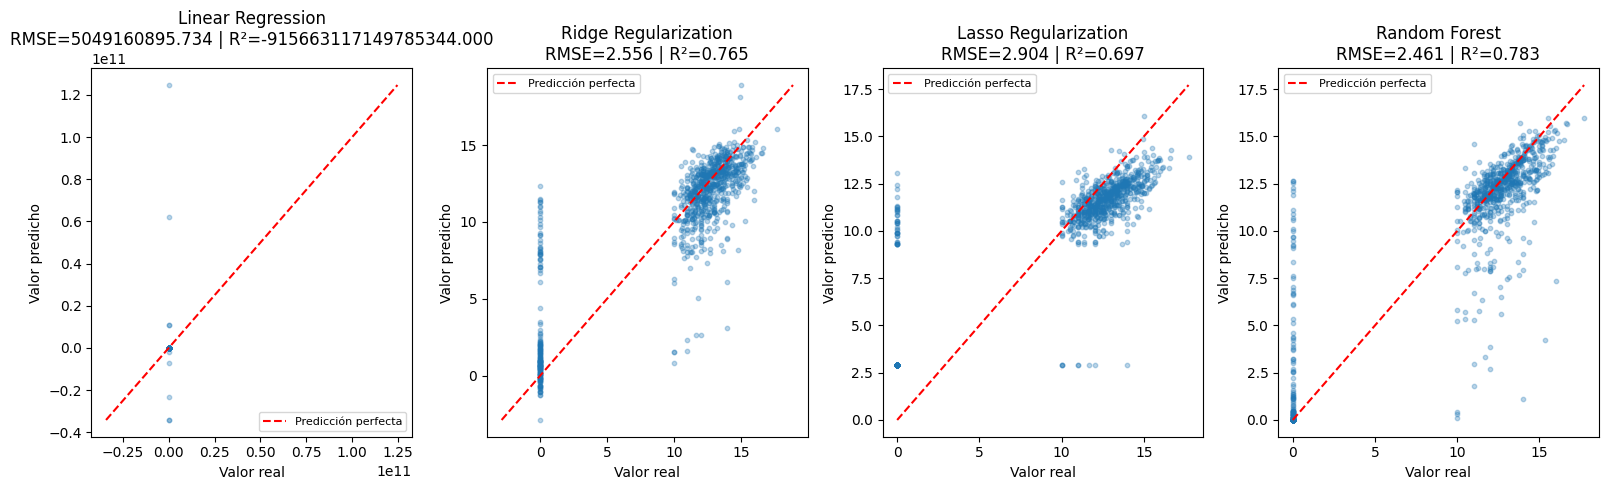

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (nombre, vals) in zip(axes, resultados.items()):
    y_pred = vals['y_pred']
    ax.scatter(y_test, y_pred, alpha=0.3, s=10, color='tab:blue')
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Predicción perfecta')
    ax.set_title(f'{nombre}\nRMSE={vals["rmse"]:.3f} | R²={vals["r2"]:.3f}')
    ax.set_xlabel('Valor real')
    ax.set_ylabel('Valor predicho')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

> Linear Regression no predice bien los valores: el eje y llega hasta 1.2e11 y no se ven puntos cerca de la diagonal de la predicción perfecta.

> Ridge y Lasso agrupan los puntos cerca de la diagonal, aunque Ridge tiende a sobreestimar alumnos con nota 0, y Lasso, al penalizar más agresivamente, comprime las predicciones hacia la media: sobreestima los ceros y subestima las notas altas.

> Random Forest tiene la nube de puntos mejor ajustada, aunque el patrón de valor_real=0 persiste. Esto nos indica que ningún modelo es capaz de predecir bien los casos extremos.

### Distribución de errores (residuos)
Se analiza la distribución de los residuos (error = real − predicho) de cada modelo. Lo deseable es una distribución centrada en 0 y simétrica.

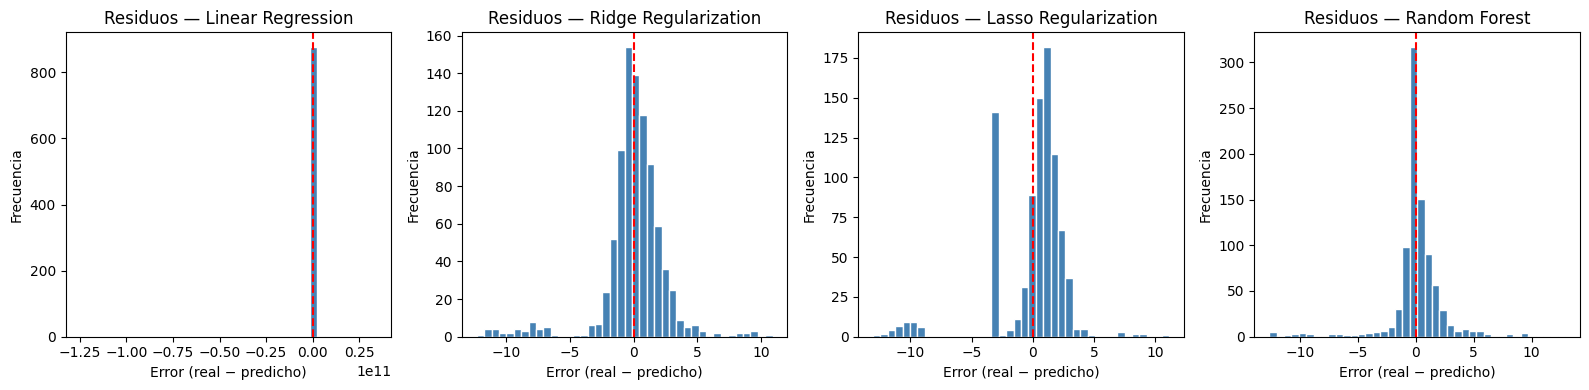

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (nombre, vals) in zip(axes, resultados.items()):
    residuos = y_test.values - vals['y_pred']
    ax.hist(residuos, bins=40, color='steelblue', edgecolor='white')
    ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(f'Residuos — {nombre}')
    ax.set_xlabel('Error (real − predicho)')
    ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

> La barra centrada en 0 en Linear Regression no significa que los errores sean pequeños, sino que son tan grandes que comparados entre sí, parecen todos iguales. 

> El resto de modelos tienen distribuciones centradas en 0 (lo esperado), pero tienen colas con masas centradas en -10 que representan los valores extremos de los que se hablaba antes. El mejor, sin embargo, sigue siendo Random Forest.

### Importancia de variables
Se analiza qué variables son más determinantes en cada modelo. Para Random Forest se usa `feature_importances_`; para los modelos lineales, los coeficientes en valor absoluto.

- Linear Regression -


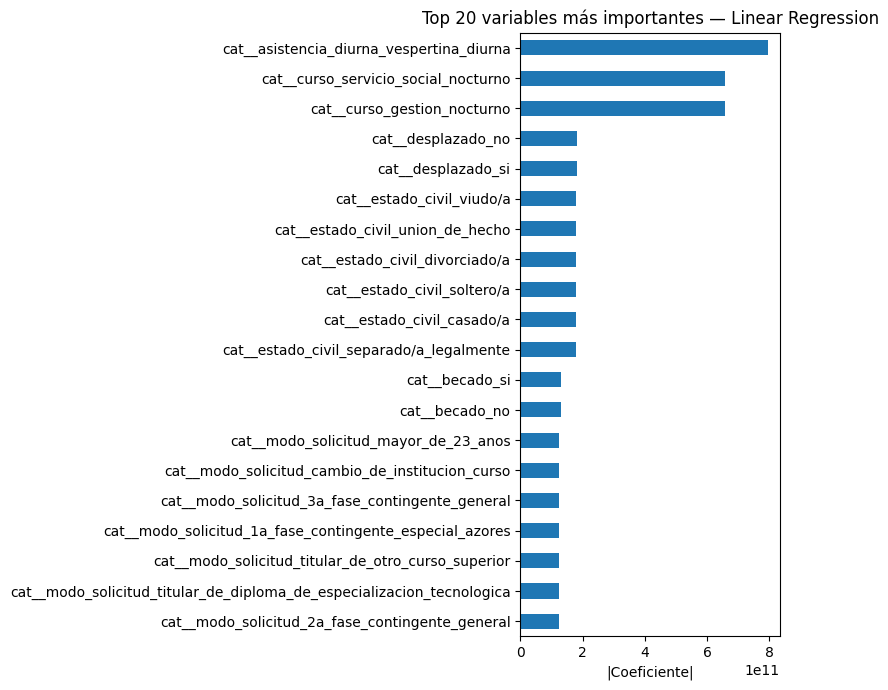

- Ridge Regularization -


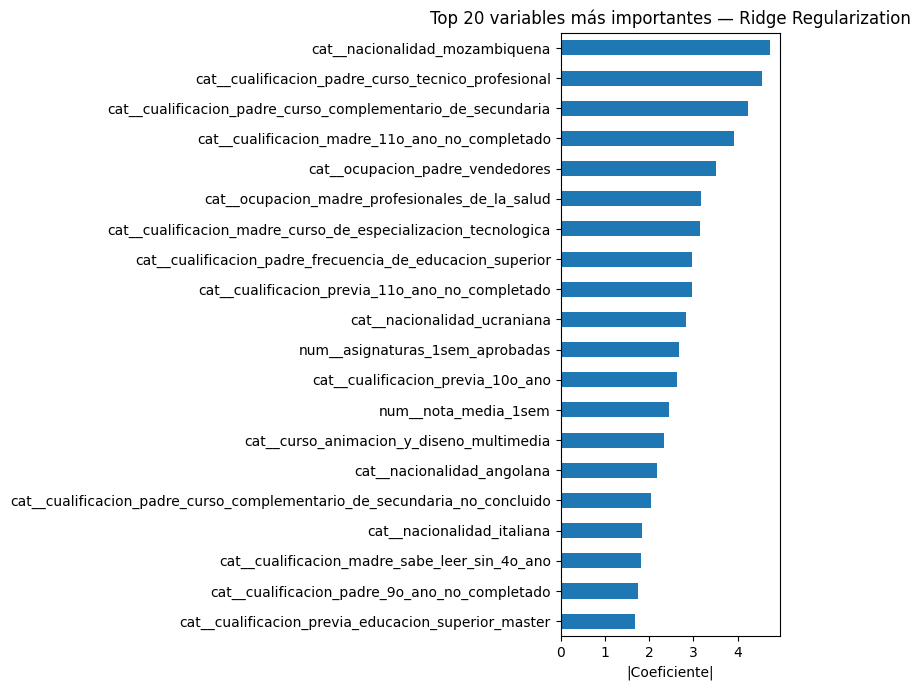

- Lasso Regularization -
Variables seleccionadas por Lasso: 2 de 240

num__nota_media_1sem               3.015119
num__asignaturas_1sem_aprobadas    0.447313
dtype: float64


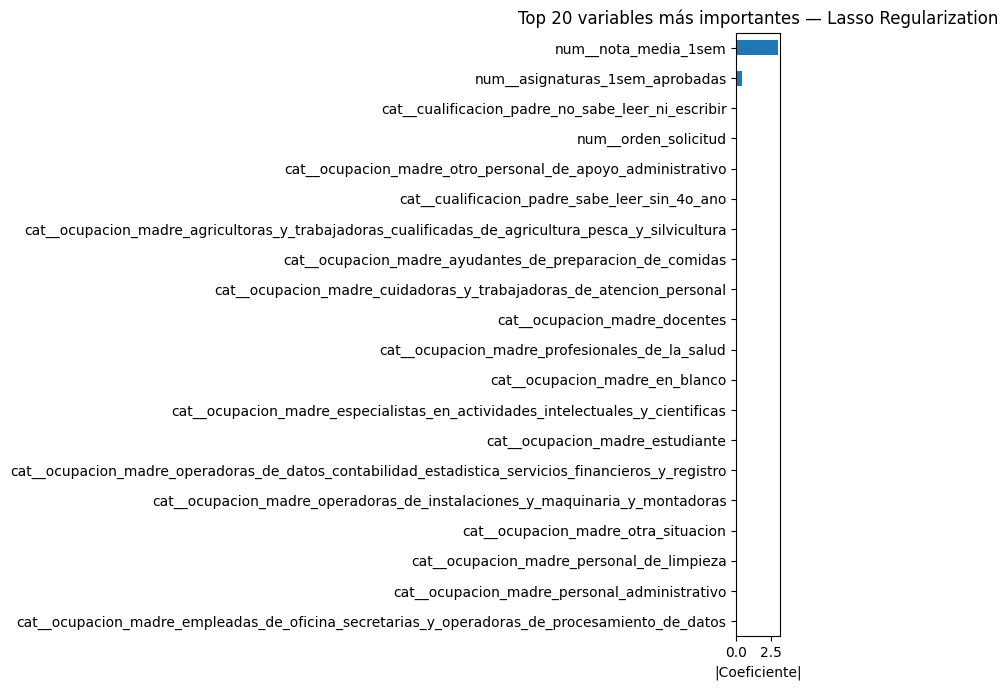

- Random Forest -


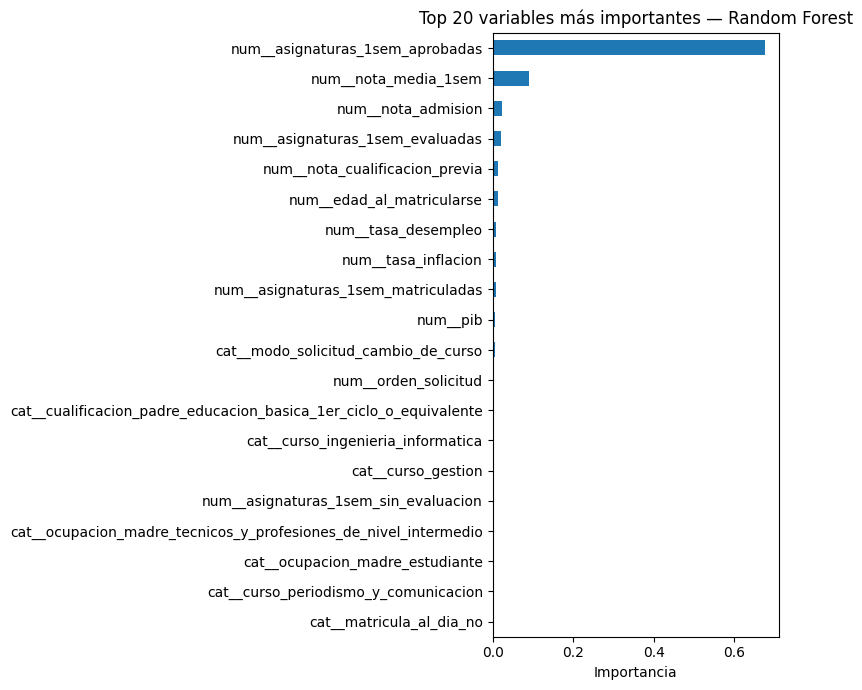

In [9]:
for nombre, modelo in modelos.items():
    print(f'- {nombre} -')

    feature_names = preprocessor.get_feature_names_out()

    if nombre == 'Lasso Regularization':
        coeficientes = pd.Series(modelo.coef_, index=feature_names)
        variables_seleccionadas = coeficientes[coeficientes != 0].sort_values(key=abs, ascending=False)
        print(f"Variables seleccionadas por Lasso: {len(variables_seleccionadas)} de {len(feature_names)}\n")
        print(variables_seleccionadas)
    
    if hasattr(modelo, 'feature_importances_'):
        importancias = pd.Series(modelo.feature_importances_, index=feature_names)
        label_x = 'Importancia'
    elif hasattr(modelo, 'coef_'):
        importancias = pd.Series(np.abs(modelo.coef_), index=feature_names)
        label_x = '|Coeficiente|'

    top20 = importancias.sort_values(ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(8, 7))
    top20.sort_values().plot(kind='barh', ax=ax, color='tab:blue')
    ax.set_title(f'Top 20 variables más importantes — {nombre}')
    ax.set_xlabel(label_x)
    plt.tight_layout()
    plt.show()

> Las variables importantes para cada modelo son interesantes. Es importante ir uno a uno para ver qué sucede en estos casos.

> El OneHotEncoding hace que haya cientos de variables categóricas, haciendo que para Linear Regression sea muy probable que en el top 20, todas ellas sean categóricas. Esto no dice mucho ya que las predicciones de este modelo no son precisas.

> Sin embargo, con Ridge ocurre lo mismo, pero éste sí produce predicciones correctas. Eso ocurre ya que, como ningún peso se reduce a 0, hay tantas variables categóricas que acumulan ruido y en el top 20 no salen las realmente importantes, que son las numéricas. En estos casos lo más probable es que en las variables seleccionadas (como nacionalidad mozambiqueña o la cualificacion del padre como tecnico profesional) simplemente haya menos instancias, y Ridge no las penaliza lo suficiente.

> Lasso fuerza ciertos coeficientes a 0, y de hecho, lo hace con todas las variables menos nota_media_1sem y asignaturas_1sem_aprobadas. Esto indica que, con este nivel de regularización (alpha=1), el resto de variables aporta poco para predecir la nota del 2º semestre una vez se controlan esas dos.

> Random Forest es el que mejor refleja la importancia de las variables. Mide cuánto reduce la impureza cada variable al usarse en las divisiones de los árboles, y el hecho de que salgan las mismas que con Lasso refuerza la conclusión de que esas son las que más pesan.

### Guardar modelos y predicciones
Se guardan los cuatro modelos entrenados y sus predicciones sobre el test.

In [10]:
# Guardar modelos
joblib.dump(modelos['Linear Regression'], '../models/linear_regression.pkl')
joblib.dump(modelos['Ridge Regularization'], '../models/ridge.pkl')
joblib.dump(modelos['Lasso Regularization'], '../models/lasso.pkl')
joblib.dump(modelos['Random Forest'], '../models/random_forest_reg.pkl')

# Guardar predicciones
for nombre, vals in resultados.items():
    nombre_fichero = nombre.lower().replace(' ', '_')
    pred_df = pd.DataFrame({
        'y_real': y_test.values,
        'y_pred': vals['y_pred']
    })
    pred_df.to_csv(f'../predictions/pred_regresion_{nombre_fichero}.csv', index=False)